In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

In [26]:
df = pd.read_csv("Tweets.csv")

# Keep only required columns
df = df[['text', 'airline_sentiment']]

print(df.head())

                                                text airline_sentiment
0                @VirginAmerica What @dhepburn said.           neutral
1  @VirginAmerica plus you've added commercials t...          positive
2  @VirginAmerica I didn't today... Must mean I n...           neutral
3  @VirginAmerica it's really aggressive to blast...          negative
4  @VirginAmerica and it's a really big bad thing...          negative


In [27]:
print("Shape:", df.shape)

print("\nInformation")
print(df.info())

print("\nDescription")
print(df.describe(include='all'))

Shape: (14640, 2)

Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   text               14640 non-null  object
 1   airline_sentiment  14640 non-null  object
dtypes: object(2)
memory usage: 228.9+ KB
None

Description
                  text airline_sentiment
count            14640             14640
unique           14427                 3
top     @united thanks          negative
freq                 6              9178


In [28]:
print(df.isnull().sum())

text                 0
airline_sentiment    0
dtype: int64


In [29]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 188


In [30]:
df = df.drop_duplicates()

In [31]:
df["tweet_length"] = df["text"].apply(len)

df["word_count"] = df["text"].apply(lambda x: len(x.split()))

In [32]:
print(df.head())

                                                text airline_sentiment  \
0                @VirginAmerica What @dhepburn said.           neutral   
1  @VirginAmerica plus you've added commercials t...          positive   
2  @VirginAmerica I didn't today... Must mean I n...           neutral   
3  @VirginAmerica it's really aggressive to blast...          negative   
4  @VirginAmerica and it's a really big bad thing...          negative   

   tweet_length  word_count  
0            35           4  
1            72           9  
2            71          12  
3           126          17  
4            55          10  


In [33]:
encoder = LabelEncoder()

df["label"] = encoder.fit_transform(df["airline_sentiment"])

print(encoder.classes_)

['negative' 'neutral' 'positive']


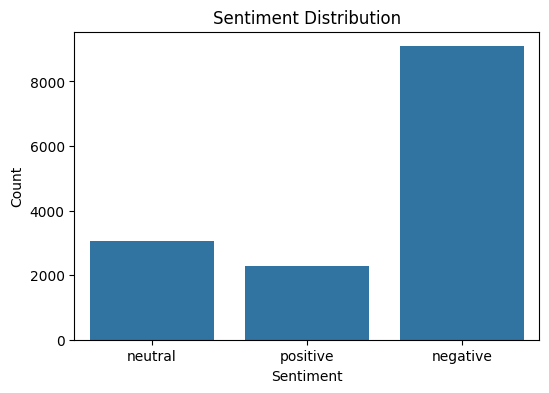

In [34]:
plt.figure(figsize=(6,4))

sns.countplot(x="airline_sentiment", data=df)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")

plt.show()

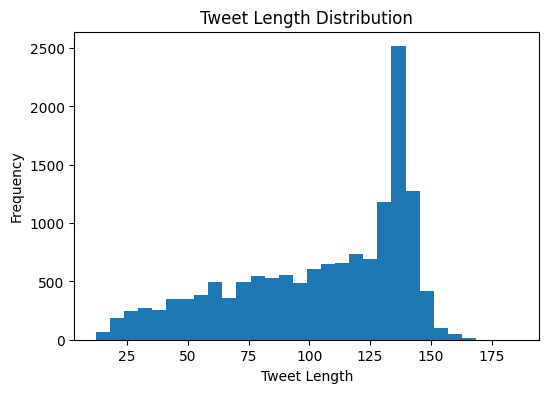

In [35]:
plt.figure(figsize=(6,4))

plt.hist(df["tweet_length"], bins=30)

plt.title("Tweet Length Distribution")
plt.xlabel("Tweet Length")
plt.ylabel("Frequency")

plt.show()

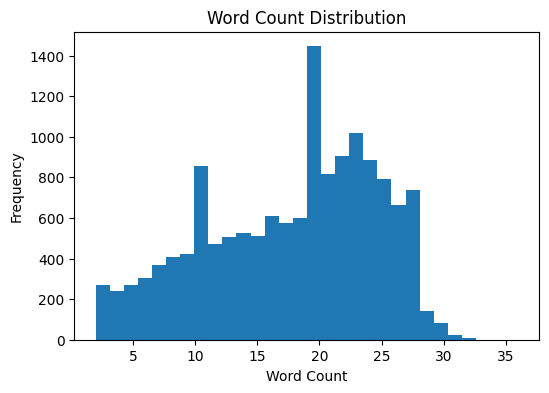

In [36]:
plt.figure(figsize=(6,4))

plt.hist(df["word_count"], bins=30)

plt.title("Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

plt.show()

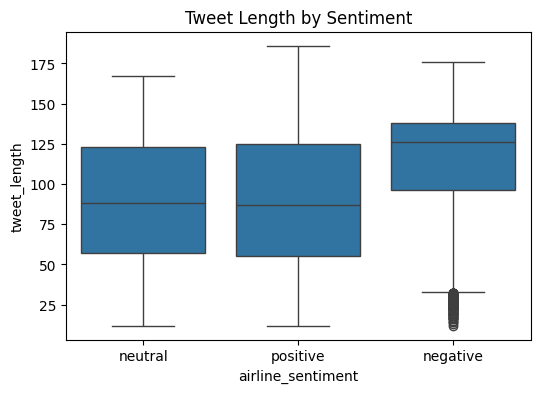

In [37]:
plt.figure(figsize=(6,4))

sns.boxplot(x="airline_sentiment",
            y="tweet_length",
            data=df)

plt.title("Tweet Length by Sentiment")

plt.show()

# Key Insights

1. The dataset contains three sentiment classes: **Negative (9178)**, **Neutral (3099)**, and **Positive (2363)**.

2. Negative tweets are the majority class, while positive tweets are the minority class, indicating class imbalance.

3. Most tweets are short, as shown by the tweet length and word count distributions.

4. Negative tweets have a higher median tweet length and greater variation than positive and neutral tweets, indicating that users often provide more detailed negative feedback.

5. The engineered features (**tweet_length** and **word_count**) help analyze tweet characteristics before training the Simple RNN model.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.2,
    random_state=42
)

In [39]:
tokenizer = Tokenizer(num_words=5000)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

In [40]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=50
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=50
)

print(X_train_pad.shape)

print(X_test_pad.shape)

(11561, 50)
(2891, 50)


In [41]:
n_classes = len(np.unique(y_train))

model = Sequential()

model.add(Embedding(5000,32,input_length=50))

model.add(SimpleRNN(32))

model.add(Dense(n_classes,
                activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [42]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [43]:
model.build(input_shape=(None,50))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,179 (633.51 KB)

 Trainable params: 162,179 (633.51 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
289/289 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.6995 - loss: 0.7155 - val_accuracy: 0.7445 - val_loss: 0.6243
Epoch 2/5
289/289 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8120 - loss: 0.4867 - val_accuracy: 0.7626 - val_loss: 0.5903
Epoch 3/5
289/289 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8861 - loss: 0.3181 - val_accuracy: 0.7713 - val_loss: 0.6053
Epoch 4/5
289/289 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9456 - loss: 0.1736 - val_accuracy: 0.7648 - val_loss: 0.7046
Epoch 5/5
289/289 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9745 - loss: 0.0930 - val_accuracy: 0.7523 - val_loss: 0.8373


In [45]:
loss,accuracy = model.evaluate(
    X_test_pad,
    y_test
)

print("Test Accuracy:",accuracy)

91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7471 - loss: 0.8327
Test Accuracy: 0.7471463084220886


In [46]:
prediction = model.predict(X_test_pad)

predicted = np.argmax(prediction,axis=1)

print("Actual")

print(encoder.inverse_transform(y_test[:10]))

print("Predicted")

print(encoder.inverse_transform(predicted[:10]))

91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Actual
['neutral' 'negative' 'negative' 'positive' 'positive' 'positive'
 'negative' 'negative' 'neutral' 'positive']
Predicted
['negative' 'negative' 'negative' 'negative' 'positive' 'positive'
 'negative' 'neutral' 'negative' 'positive']


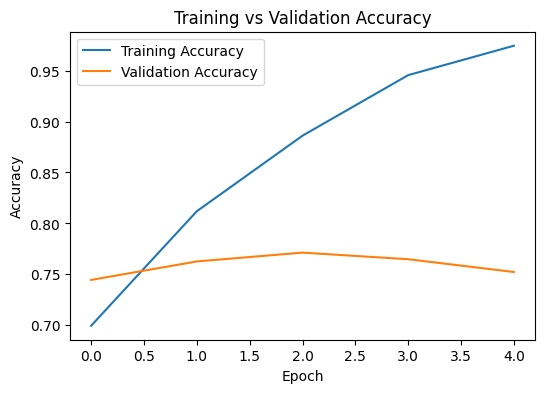

In [47]:
plt.figure(figsize=(6,4))

plt.plot(history.history["accuracy"],
         label="Training Accuracy")

plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

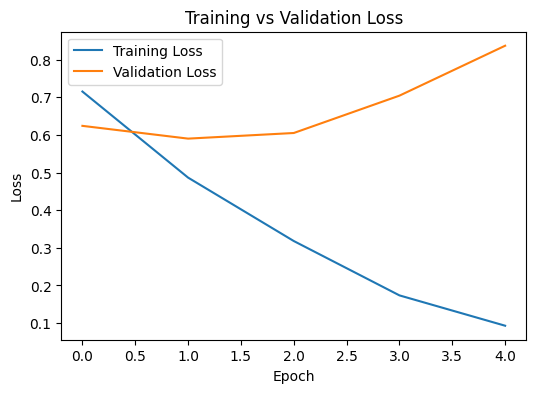

In [48]:
plt.figure(figsize=(6,4))

plt.plot(history.history["loss"],
         label="Training Loss")

plt.plot(history.history["val_loss"],
         label="Validation Loss")

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

Vanishing Gradient Problem: A plain RNN struggles with long sequences because the gradients become very small during backpropagation, making it difficult to learn long-term dependencies. As a result, the network tends to remember only recent information.